# 03 Style clusters: Gaussian mixture on the first 5 principal components

Inputs: `features.clustering_matrix(profiles)` (8 within-division z-scores of shrunk style features, eligible fighters, full careers),
projected onto the first 5 principal components (85% of the variance; `notebooks/02_pca.ipynb`). Model: Gaussian mixture with full
covariance (`src/clustering.py`). Clusters are numbered by size (cluster 1 = largest) and are **deliberately not named**.

The fitted models and per-fighter probabilities are written by `python src/clustering.py`. This notebook refits the same models with the
same seed to analyse them.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
import features as F
import clustering as CL

pd.set_option("display.width", 220, "display.max_columns", 40, "display.precision", 3)
plt.rcParams.update({"figure.dpi": 80, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})

ff = F.load_fighter_fights()
profiles = F.build_profiles(None, ff)
X = F.clustering_matrix(profiles)
pca = CL.fit_pca(X)
Z = pca.transform(X.values)
info = profiles.set_index("fighter_id").loc[X.index]
print(f"{len(X):,} eligible fighters; {CL.N_COMPONENTS} PCs explain {pca.explained_variance_ratio_.sum():.1%}")
FAMOUS = ["Georges St-Pierre", "Khabib Nurmagomedov", "Jon Jones", "Anderson Silva", "Conor McGregor", "Israel Adesanya",
          "Max Holloway", "Demian Maia", "Charles Oliveira", "Merab Dvalishvili", "Jose Aldo", "Francis Ngannou", "Amanda Nunes",
          "Valentina Shevchenko", "Zhang Weili", "Joanna Jedrzejczyk", "Alexander Volkanovski", "Kamaru Usman", "Nate Diaz",
          "Jailton Almeida", "Sean Strickland", "Demetrious Johnson", "Daniel Cormier", "Stipe Miocic", "Dustin Poirier",
          "Islam Makhachev", "Alex Pereira", "Justin Gaethje", "Chael Sonnen", "Matt Hughes"]

1,240 eligible fighters; 5 PCs explain 85.2%


## 1. Choosing the number of clusters

For each k: **BIC** of the full-data fit (lower is better), and **bootstrap stability**. Refit on 50 resamples of fighters (with
replacement), assign every fighter with the refit model, and compare with the full-data assignment using the adjusted Rand index
(ARI: 1 = identical partition, 0 = chance). The PCA is held fixed during the bootstrap.

The requested range is k = 3–10. k = 1 and 2 are included as reference rows (k = 1 is trivially "stable").

,bic,aic,ari_mean,ari_sd,ari_p10,smallest_cluster,mean_max_prob,in requested range
k,,,,,,,,
1,18671.011,18568.554,1.000,0.000,1.000,1240,1.000,False
2,18295.947,18085.909,0.808,0.066,0.719,528,0.875,False
3,18220.923,17903.305,0.701,0.098,0.551,294,0.806,True
4,18282.925,17857.727,0.486,0.150,0.334,258,0.765,True
5,18382.397,17849.619,0.338,0.096,0.244,152,0.708,True
6,18467.646,17827.287,0.344,0.081,0.249,107,0.693,True
7,18569.322,17821.383,0.321,0.075,0.220,69,0.677,True
8,18670.740,17815.222,0.348,0.085,0.242,56,0.712,True
9,18775.159,17812.060,0.263,0.049,0.208,52,0.712,True


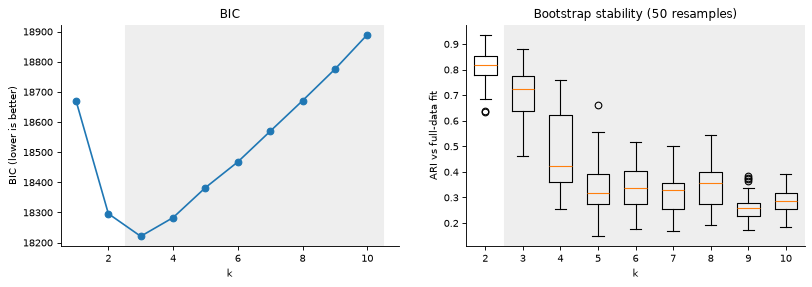

Within k = 3-10: lowest BIC at k = 3, most stable at k = 3.
Recommended k = 3; next-best k = 4.


In [2]:
summary, boot = CL.select_k(Z, ks=range(1, 11), n_boot=50)
show = summary.copy()
show["in requested range"] = show.index >= 3
display(show.round(3))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.6))
a1.plot(summary.index, summary["bic"], marker="o")
a1.set_xlabel("k"); a1.set_ylabel("BIC (lower is better)"); a1.set_title("BIC")
data = [boot.loc[boot["k"] == k, "ari"] for k in range(2, 11)]
a2.boxplot(data, positions=range(2, 11), widths=0.6)
a2.set_xlabel("k"); a2.set_ylabel("ARI vs full-data fit"); a2.set_title("Bootstrap stability (50 resamples)")
for a in (a1, a2):
    a.axvspan(2.5, 10.5, color="#eeeeee", zorder=-1)
plt.show()

rng = summary.loc[3:10]
print(f"Within k = 3-10: lowest BIC at k = {rng['bic'].idxmin()}, most stable at k = {rng['ari_mean'].idxmax()}.")
print(f"Recommended k = {CL.CHOSEN_K}; next-best k = {CL.RUNNER_UP_K}.")

**Recommendation: k = 3, with k = 4 as the next-best option.**

- Within k = 3–10, k = 3 has both the **lowest BIC** and the **highest bootstrap stability** (mean ARI about 0.70). k = 4 is second on both
  (ARI about 0.49).
- From k = 5 on, stability falls to about 0.25–0.35. Partitions into 5+ groups mostly don't reproduce on resampled data, so I wouldn't
  interpret them.
- Even k = 3 is only **moderately** stable (ARI 0.8+ is usually called stable). BIC strongly prefers a mixture to a single Gaussian
  (k = 1), so the style space isn't one blob, but the groups overlap heavily. The **membership probabilities** (soft assignments) are more
  informative than the hard labels, especially for fighters between clusters.
- k = 2 has a slightly worse BIC than k = 3 and is more stable. It's outside the requested range and is shown only for context.

## 2. Fit the recommended and next-best models

k = 3: sizes {1: 510, 2: 436, 3: 294}; mean max probability 0.81; share of fighters with max probability < 0.6: 17%
k = 4: sizes {1: 398, 2: 305, 3: 279, 4: 258}; mean max probability 0.77; share of fighters with max probability < 0.6: 21%


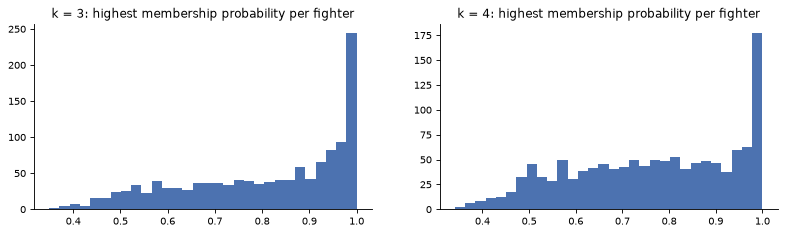

In [3]:
models = {k: CL.fit_style_model(profiles, k) for k in (CL.CHOSEN_K, CL.RUNNER_UP_K)}
assign = {k: m.assign(profiles).set_index("fighter_id").loc[X.index] for k, m in models.items()}
for k, a in assign.items():
    sizes = a["cluster"].value_counts().sort_index()
    print(f"k = {k}: sizes {sizes.to_dict()}; mean max probability {a['max_prob'].mean():.2f}; "
          f"share of fighters with max probability < 0.6: {(a['max_prob'] < 0.6).mean():.0%}")
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
for ax, (k, a) in zip(axes, assign.items()):
    ax.hist(a["max_prob"], bins=30, color="#4C72B0")
    ax.set_title(f"k = {k}: highest membership probability per fighter")
plt.show()

## 3. Baseline: k-means at the same k

k-means on the same 5 PC scores. Agreement is the ARI and the share of fighters in matching clusters after optimal label matching.

In [4]:
for k, a in assign.items():
    gmm_labels = a["cluster"].values - 1
    r = CL.kmeans_agreement(Z, gmm_labels, k)
    ct = pd.DataFrame(r["crosstab"], index=[f"GMM {i + 1}" for i in range(k)], columns=[f"k-means {j + 1}" for j in range(k)])
    print(f"k = {k}: ARI = {r['ari']:.2f}; fighters in matched clusters = {r['matched_share']:.0%}")
    display(ct)

k = 3: ARI = 0.34; fighters in matched clusters = 72%


,k-means 1,k-means 2,k-means 3
GMM 1,79,327,104
GMM 2,340,2,94
GMM 3,49,23,222


k = 4: ARI = 0.31; fighters in matched clusters = 63%


,k-means 1,k-means 2,k-means 3,k-means 4
GMM 1,130,196,49,23
GMM 2,2,111,1,191
GMM 3,200,1,78,0
GMM 4,19,23,197,19


## 4. Cluster profiles (k = 3)

Means over fighters hard-assigned to each cluster. **Raw units** are the shrunk features (shares are fractions; rates are per 15 min or
per minute). **Division z-scores** are the within-division standardized values, which are what the clustering saw. Skill measures are
shown for context only; they weren't used to fit the clusters.

In [5]:
RAW = F.STYLE_FEATURES
Zc = [f"z_{f}" for f in F.STYLE_FEATURES]
def profile_tables(k):
    a = assign[k].join(info[RAW + F.SKILL_MEASURES + Zc + ["fight_time_min"]])
    g = a.groupby("cluster")
    raw = g[RAW].mean()
    raw.insert(0, "fighters", g.size())
    allrow = a[RAW].mean().to_frame("all").T
    allrow.insert(0, "fighters", len(a))
    raw = pd.concat([raw, allrow])
    z = g[Zc].mean().set_axis(RAW, axis=1)
    skill = pd.concat([g[F.SKILL_MEASURES + ["fight_time_min"]].mean(), a[F.SKILL_MEASURES + ["fight_time_min"]].mean().to_frame("all").T])
    return raw, z, skill

raw3, z3, skill3 = profile_tables(CL.CHOSEN_K)
print("Raw units (shrunk features):"); display(raw3)
print("Division z-scores:"); display(z3.style.background_gradient(cmap="RdBu_r", vmin=-1.5, vmax=1.5, axis=None).format("{:.2f}"))
print("Skill measures (not used in clustering):"); display(skill3)

Raw units (shrunk features):


,fighters,pos_distance,pos_clinch,pos_ground,tgt_head,tgt_body,tgt_leg,td_att_per15,ctrl_share,sub_att_per15,pace
1,510,0.790,0.090,0.120,0.798,0.123,0.078,5.093,0.266,0.633,7.254
2,436,0.863,0.069,0.067,0.781,0.128,0.091,2.920,0.155,0.456,8.750
3,294,0.809,0.108,0.083,0.725,0.162,0.113,3.647,0.196,0.458,7.938
all,1240,0.820,0.087,0.093,0.775,0.134,0.091,3.986,0.210,0.529,7.942


Division z-scores:


,pos_distance,pos_clinch,pos_ground,tgt_head,tgt_body,tgt_leg,td_att_per15,ctrl_share,sub_att_per15,pace
cluster,,,,,,,,,,
1,-0.50,0.11,0.60,0.49,-0.34,-0.42,0.62,0.68,0.60,-0.45
2,0.71,-0.57,-0.56,0.13,-0.20,-0.00,-0.60,-0.68,-0.41,0.54
3,-0.19,0.66,-0.22,-1.04,0.88,0.73,-0.19,-0.17,-0.42,-0.01


Skill measures (not used in clustering):


,str_acc,str_def,td_acc,td_def,kd_per15,str_diff_per_min,fight_time_min
1,0.450,0.542,0.395,0.615,0.252,-0.109,123.267
2,0.441,0.551,0.375,0.642,0.503,-0.029,116.247
3,0.489,0.547,0.377,0.642,0.349,0.394,131.768
all,0.456,0.546,0.384,0.631,0.363,0.038,122.814


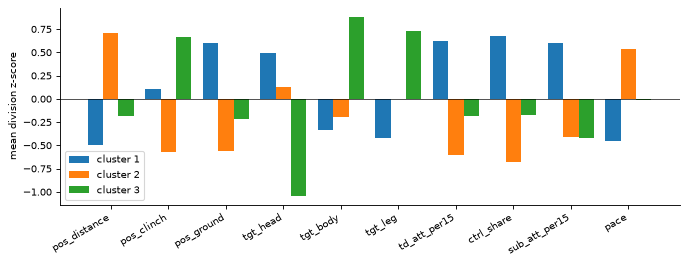

In [6]:
fig, ax = plt.subplots(figsize=(10, 3.2))
w = 0.8 / len(z3)
for i, (c, row) in enumerate(z3.iterrows()):
    ax.bar(np.arange(len(RAW)) + i * w, row.values, width=w, label=f"cluster {c}")
ax.set_xticks(np.arange(len(RAW)) + w * (len(z3) - 1) / 2, RAW, rotation=30, ha="right")
ax.axhline(0, color="k", lw=0.6)
ax.set_ylabel("mean division z-score")
ax.legend()
plt.show()

### Most representative fighters and well-known mixed members (k = 3)

Top 10 per cluster by membership probability. Then well-known fighters whose highest probability is below 0.8.

In [7]:
def representatives(k, n=10):
    a = assign[k]
    cols = {}
    for c in range(1, k + 1):
        top = a.nlargest(n, f"p_cluster_{c}")
        cols[f"cluster {c}"] = [f"{r.fighter_name} ({getattr(r, f'p_cluster_{c}'):.2f}, {r.division.replace('weight', 'wt')})" for r in top.itertuples()]
    return pd.DataFrame(cols, index=range(1, n + 1))

def mixed(k, threshold=0.8):
    a = assign[k]
    m = a[a["fighter_name"].isin(FAMOUS)]
    pc = [f"p_cluster_{c}" for c in range(1, k + 1)]
    return m.loc[m["max_prob"] < threshold, ["fighter_name", "division", "cluster"] + pc].sort_values("fighter_name").set_index("fighter_name").round(2)

display(representatives(CL.CHOSEN_K))
fam = assign[CL.CHOSEN_K][assign[CL.CHOSEN_K]["fighter_name"].isin(FAMOUS)]
print(f"Well-known fighters: {len(fam)} eligible; {int((fam['max_prob'] < 0.8).sum())} have max probability < 0.8")
display(mixed(CL.CHOSEN_K))
print("All well-known fighters, hard cluster (k = 3):")
display(fam.groupby("cluster")["fighter_name"].apply(lambda s: ", ".join(sorted(s))).to_frame())

,cluster 1,cluster 2,cluster 3
1,"Jaqueline Amorim (1.00, Women's Strawwt)","Sean Strickland (1.00, Middlewt)","Chris Gutierrez (1.00, Bantamwt)"
2,"Charles Oliveira (1.00, Lightwt)","Nasrat Haqparast (1.00, Lightwt)","Chidi Njokuani (1.00, Welterwt)"
3,"Renato Sobral (1.00, Light Heavywt)","Nam Phan (1.00, Featherwt)","Caol Uno (1.00, Lightwt)"
4,"TJ Waldburger (1.00, Welterwt)","Esteban Ribovics (1.00, Lightwt)","Fabio Maldonado (1.00, Light Heavywt)"
5,"Frank Mir (1.00, Heavywt)","Eddie Wineland (1.00, Bantamwt)","Michel Pereira (1.00, Middlewt)"
6,"Stefan Struve (1.00, Heavywt)","Joshua Van (0.99, Flywt)","Demetrious Johnson (1.00, Flywt)"
7,"Paul Sass (1.00, Lightwt)","Alex Morono (0.99, Welterwt)","Loma Lookboonmee (1.00, Women's Strawwt)"
8,"Dustin Hazelett (1.00, Welterwt)","Sean Spencer (0.99, Welterwt)","John Lineker (1.00, Bantamwt)"
9,"Rousimar Palhares (1.00, Middlewt)","Sam Stout (0.99, Lightwt)","Brandon Vera (1.00, Light Heavywt)"
10,"Rani Yahya (1.00, Bantamwt)","Calvin Kattar (0.99, Featherwt)","Bryan Battle (1.00, Welterwt)"


Well-known fighters: 30 eligible; 3 have max probability < 0.8


,division,cluster,p_cluster_1,p_cluster_2,p_cluster_3
fighter_name,,,,,
Daniel Cormier,Light Heavyweight,1,0.69,0.05,0.25
Francis Ngannou,Heavyweight,2,0.26,0.68,0.06
Kamaru Usman,Welterweight,1,0.60,0.00,0.40


All well-known fighters, hard cluster (k = 3):


,fighter_name
cluster,
1,"Amanda Nunes, Chael Sonnen, Charles Oliveira, ..."
2,"Conor McGregor, Francis Ngannou, Jose Aldo, Ma..."
3,"Alex Pereira, Alexander Volkanovski, Anderson ..."


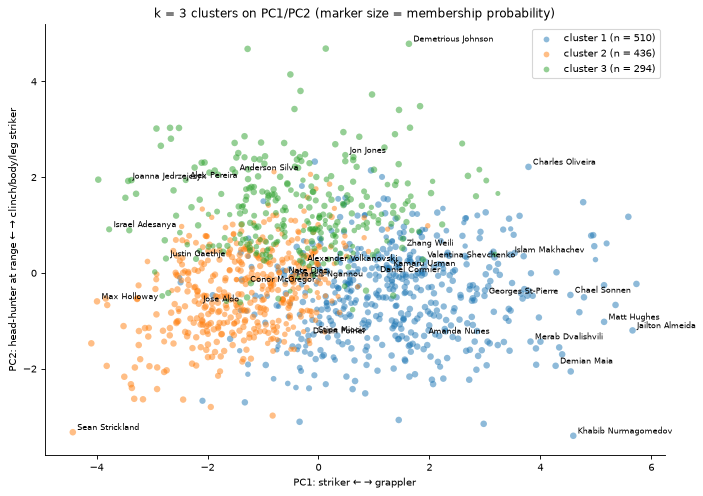

In [8]:
a = assign[CL.CHOSEN_K]
fig, ax = plt.subplots(figsize=(10, 7))
for c in range(1, CL.CHOSEN_K + 1):
    s = a[a["cluster"] == c]
    ax.scatter(s["PC1"], s["PC2"], s=10 + 25 * s["max_prob"], alpha=0.5, lw=0, label=f"cluster {c} (n = {len(s)})")
for r in fam.itertuples():
    ax.annotate(r.fighter_name, (r.PC1, r.PC2), xytext=(4, 2), textcoords="offset points", fontsize=7.5)
ax.set_xlabel("PC1: striker ← → grappler"); ax.set_ylabel("PC2: head-hunter at range ← → clinch/body/leg striker")
ax.set_title("k = 3 clusters on PC1/PC2 (marker size = membership probability)")
ax.legend()
plt.show()

## 5. Confounding checks (k = 3): division and era

The style features are standardized within division, so the clusters shouldn't track weight class. They are **not** standardized
by era, so this is the more important check. Era = the median year of the fighter's UFC fights since 2000. Cramér's V summarizes
association: 0 = none, 1 = the cluster is fully determined by the variable. Under about 0.1 is usually read as negligible, and about
0.1–0.3 as weak.

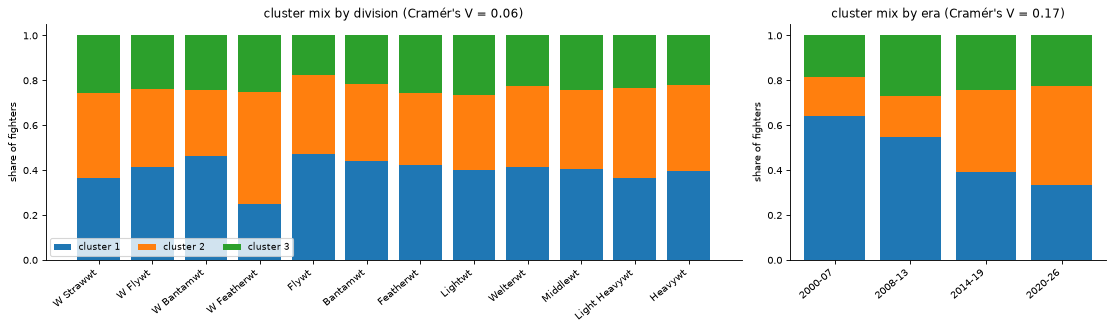

Cluster mix by division, row % (Cramér's V = 0.06):


cluster,fighters,1,2,3
division,,,,
Women's Strawweight,63,37%,38%,25%
Women's Flyweight,46,41%,35%,24%
Women's Bantamweight,41,46%,29%,24%
Women's Featherweight,4,25%,50%,25%
Flyweight,74,47%,35%,18%
Bantamweight,120,44%,34%,22%
Featherweight,128,42%,32%,26%
Lightweight,206,40%,33%,27%
Welterweight,186,41%,36%,23%


Cluster mix by era, row % (Cramér's V = 0.17):


cluster,fighters,1,2,3
event_date,,,,
2000-07,70,64%,17%,19%
2008-13,240,55%,18%,27%
2014-19,415,39%,37%,24%
2020-26,515,33%,44%,23%
all fighters,1240,41%,35%,24%


In [9]:
DIV_ORDER = ["Women's Strawweight", "Women's Flyweight", "Women's Bantamweight", "Women's Featherweight", "Flyweight",
             "Bantamweight", "Featherweight", "Lightweight", "Welterweight", "Middleweight", "Light Heavyweight", "Heavyweight"]
med_year = ff[ff["fighter_id"].isin(X.index)].groupby("fighter_id")["event_date"].apply(lambda s: int(s.str[:4].astype(int).median()))
ERA_BINS, ERA_LABELS = [1999, 2007, 2013, 2019, 2026], ["2000-07", "2008-13", "2014-19", "2020-26"]
era = pd.cut(med_year.reindex(X.index), ERA_BINS, labels=ERA_LABELS)

def cramers_v(ct):
    chi2 = chi2_contingency(ct)[0]
    return np.sqrt(chi2 / ct.values.sum() / (min(ct.shape) - 1))

def confound(k):
    a = assign[k]
    out = {}
    for name, var, order in (("division", info["division"], DIV_ORDER), ("era", era, ERA_LABELS)):
        ct = pd.crosstab(var, a["cluster"]).reindex([o for o in order if o in set(var.dropna())])
        share = ct.div(ct.sum(axis=1), axis=0)
        overall = a["cluster"].value_counts(normalize=True).sort_index()
        out[name] = (ct, share, overall, cramers_v(ct))
    return out

def show_confound(k):
    res = confound(k)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [2.2, 1]})
    for ax, (name, (ct, share, overall, v)) in zip(axes, res.items()):
        bottom = np.zeros(len(share))
        for c in share.columns:
            ax.bar(range(len(share)), share[c].values, bottom=bottom, label=f"cluster {c}")
            bottom += share[c].values
        ax.set_xticks(range(len(share)), [s.replace("Women's ", "W ").replace("weight", "wt") for s in share.index], rotation=40, ha="right")
        ax.set_ylabel("share of fighters"); ax.set_title(f"cluster mix by {name} (Cramér's V = {v:.2f})")
    axes[0].legend(ncol=k, fontsize=8, loc="lower left")
    plt.tight_layout(); plt.show()
    for name, (ct, share, overall, v) in res.items():
        t = (share * 100).round(0).astype(int).astype(str) + "%"
        t.insert(0, "fighters", ct.sum(axis=1).astype(str))
        t.loc["all fighters"] = ["%d" % ct.values.sum()] + [f"{x:.0%}" for x in overall.values]
        print(f"Cluster mix by {name}, row % (Cramér's V = {v:.2f}):")
        display(t)
    return res

conf3 = show_confound(CL.CHOSEN_K)

In [10]:
# Which features drift by era? Mean within-division z-score by era (all eligible fighters).
zt = info[Zc].set_axis(RAW, axis=1).groupby(era, observed=True).mean()
display(zt.round(2).style.background_gradient(cmap="RdBu_r", vmin=-0.6, vmax=0.6, axis=None).format("{:.2f}"))
xt = pd.crosstab(era, assign[CL.CHOSEN_K]["cluster"], normalize="columns").round(2)
print("Era mix within each cluster (column %):"); display(xt)

,pos_distance,pos_clinch,pos_ground,tgt_head,tgt_body,tgt_leg,td_att_per15,ctrl_share,sub_att_per15,pace
event_date,,,,,,,,,,
2000-07,-0.84,0.65,0.69,0.26,-0.33,-0.06,0.03,0.36,0.52,-0.62
2008-13,-0.49,0.49,0.33,0.15,-0.20,-0.02,0.17,0.23,0.34,-0.31
2014-19,0.06,-0.01,-0.07,0.01,-0.01,-0.01,-0.06,-0.10,-0.12,-0.02
2020-26,0.30,-0.30,-0.19,-0.11,0.15,0.02,-0.04,-0.08,-0.13,0.24


Era mix within each cluster (column %):


cluster,1,2,3
event_date,,,
2000-07,0.09,0.03,0.04
2008-13,0.26,0.10,0.22
2014-19,0.32,0.35,0.34
2020-26,0.34,0.52,0.39


**Reading the checks (k = 3)**

- **Division: no meaningful association** (Cramér's V about 0.06). Every division's cluster mix is within a few points of the overall mix.
  Within-division standardization did its job.
- **Era: weak but real association** (V about 0.17). Cluster 1 is over-represented among fighters whose careers centre on 2000–13, and
  cluster 2 among 2014–26. Cluster 3's share is roughly flat across eras.
- The cause is drift in the features themselves, shown in the table above. Since 2000, within-division distance share and pace have
  risen and clinch share, ground share and submission attempts have fallen, by roughly 0.6–1.1 SD between the earliest and latest
  eras. Clusters 1 and 2 sit along those same features, so part of what separates them is when a fighter fought.
- Options, if this matters for the matchup analysis: standardize features within division × era (or year) instead of division only;
  include era as a control in the matchup model; or restrict to a narrower period. This notebook doesn't change the standardization.

## 6. Next-best option: k = 4

Same tables, condensed. Then how the k = 3 clusters split into the k = 4 clusters.

In [11]:
raw4, z4, skill4 = profile_tables(CL.RUNNER_UP_K)
display(raw4)
display(z4.style.background_gradient(cmap="RdBu_r", vmin=-1.5, vmax=1.5, axis=None).format("{:.2f}"))
display(skill4)
display(representatives(CL.RUNNER_UP_K))
display(mixed(CL.RUNNER_UP_K))
ct = pd.crosstab(assign[CL.CHOSEN_K]["cluster"].rename("k = 3 cluster"), assign[CL.RUNNER_UP_K]["cluster"].rename("k = 4 cluster"))
print("k = 3 (rows) vs k = 4 (columns):"); display(ct)

,fighters,pos_distance,pos_clinch,pos_ground,tgt_head,tgt_body,tgt_leg,td_att_per15,ctrl_share,sub_att_per15,pace
1,398,0.829,0.081,0.090,0.789,0.126,0.085,3.953,0.207,0.527,7.814
2,305,0.765,0.096,0.139,0.798,0.125,0.077,5.689,0.298,0.694,6.914
3,279,0.878,0.064,0.059,0.778,0.128,0.094,2.583,0.137,0.430,9.183
4,258,0.811,0.109,0.080,0.721,0.163,0.116,3.542,0.192,0.444,8.013
all,1240,0.820,0.087,0.093,0.775,0.134,0.091,3.986,0.210,0.529,7.942


,pos_distance,pos_clinch,pos_ground,tgt_head,tgt_body,tgt_leg,td_att_per15,ctrl_share,sub_att_per15,pace
cluster,,,,,,,,,,
1,0.12,-0.15,-0.06,0.31,-0.26,-0.21,-0.02,-0.03,-0.01,-0.09
2,-0.89,0.30,0.99,0.48,-0.28,-0.47,0.96,1.07,0.97,-0.66
3,0.94,-0.74,-0.75,0.07,-0.18,0.07,-0.79,-0.90,-0.57,0.82
4,-0.15,0.68,-0.27,-1.12,0.92,0.81,-0.25,-0.24,-0.51,0.04


,str_acc,str_def,td_acc,td_def,kd_per15,str_diff_per_min,fight_time_min
1,0.443,0.545,0.383,0.622,0.373,-0.231,106.396
2,0.461,0.538,0.401,0.605,0.238,0.031,127.331
3,0.438,0.555,0.372,0.659,0.508,0.050,127.371
4,0.489,0.547,0.377,0.645,0.340,0.450,137.875
all,0.456,0.546,0.384,0.631,0.363,0.038,122.814


,cluster 1,cluster 2,cluster 3,cluster 4
1,"Ivan Salaverry (0.99, Middlewt)","Jaqueline Amorim (1.00, Women's Strawwt)","Sean Strickland (1.00, Middlewt)","Caol Uno (1.00, Lightwt)"
2,"Belal Muhammad (0.97, Welterwt)","Renato Sobral (1.00, Light Heavywt)","Nasrat Haqparast (1.00, Lightwt)","Chidi Njokuani (1.00, Welterwt)"
3,"Omari Akhmedov (0.94, Middlewt)","Charles Oliveira (1.00, Lightwt)","Nam Phan (1.00, Featherwt)","Chris Gutierrez (1.00, Bantamwt)"
4,"Elvis Sinosic (0.94, Light Heavywt)","Jailton Almeida (1.00, Heavywt)","Esteban Ribovics (1.00, Lightwt)","Fabio Maldonado (1.00, Light Heavywt)"
5,"Dominick Cruz (0.94, Bantamwt)","Khabib Nurmagomedov (1.00, Lightwt)","Santiago Ponzinibbio (0.99, Welterwt)","Alexander Volkanovski (1.00, Featherwt)"
6,"Andre Fili (0.94, Featherwt)","Chris Lytle (1.00, Welterwt)","Sam Stout (0.99, Lightwt)","Brandon Vera (1.00, Light Heavywt)"
7,"Nicholas Musoke (0.93, Welterwt)","Frank Mir (1.00, Heavywt)","Dustin Jacoby (0.99, Light Heavywt)","Michel Pereira (1.00, Middlewt)"
8,"Rafa Garcia (0.93, Lightwt)","Gillian Robertson (1.00, Women's Flywt)","Calvin Kattar (0.99, Featherwt)","John Howard (1.00, Welterwt)"
9,"Deron Winn (0.92, Middlewt)","Joe Lauzon (1.00, Lightwt)","Alex Morono (0.99, Welterwt)","Hakeem Dawodu (1.00, Featherwt)"
10,"Jared Hamman (0.92, Middlewt)","Matt Hughes (1.00, Welterwt)","Eddie Wineland (0.99, Bantamwt)","Demetrious Johnson (1.00, Flywt)"


,division,cluster,p_cluster_1,p_cluster_2,p_cluster_3,p_cluster_4
fighter_name,,,,,,
Alex Pereira,Light Heavyweight,4,0.00,0.00,0.24,0.76
Amanda Nunes,Women's Bantamweight,2,0.25,0.74,0.00,0.02
Conor McGregor,Featherweight,3,0.31,0.01,0.62,0.06
Daniel Cormier,Light Heavyweight,1,0.46,0.39,0.00,0.15
Dustin Poirier,Lightweight,1,0.56,0.41,0.01,0.02
Francis Ngannou,Heavyweight,1,0.68,0.04,0.25,0.03
Kamaru Usman,Welterweight,2,0.10,0.80,0.00,0.10
Nate Diaz,Lightweight,2,0.23,0.72,0.00,0.05


k = 3 (rows) vs k = 4 (columns):


k = 4 cluster,1,2,3,4
k = 3 cluster,,,,
1,212,297,0,1
2,149,0,275,12
3,37,8,4,245


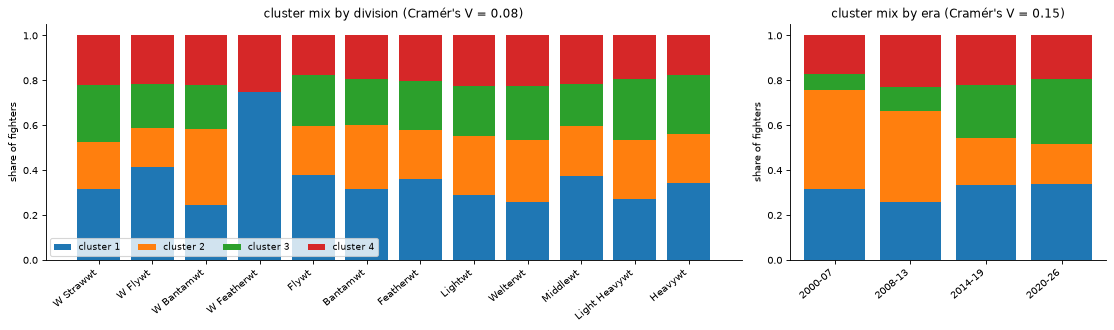

Cluster mix by division, row % (Cramér's V = 0.08):


cluster,fighters,1,2,3,4
division,,,,,
Women's Strawweight,63,32%,21%,25%,22%
Women's Flyweight,46,41%,17%,20%,22%
Women's Bantamweight,41,24%,34%,20%,22%
Women's Featherweight,4,75%,0%,0%,25%
Flyweight,74,38%,22%,23%,18%
Bantamweight,120,32%,28%,21%,19%
Featherweight,128,36%,22%,22%,20%
Lightweight,206,29%,26%,22%,22%
Welterweight,186,26%,27%,24%,23%


Cluster mix by era, row % (Cramér's V = 0.15):


cluster,fighters,1,2,3,4
event_date,,,,,
2000-07,70,31%,44%,7%,17%
2008-13,240,26%,40%,11%,23%
2014-19,415,33%,21%,23%,22%
2020-26,515,34%,17%,29%,19%
all fighters,1240,32%,25%,22%,21%


In [12]:
conf4 = show_confound(CL.RUNNER_UP_K)

## 7. Saved outputs

`python src/clustering.py` writes:

- `data/processed/cluster_probabilities.csv`: each eligible fighter's k = 3 membership probabilities, hard cluster, max probability and PC scores
- `data/processed/models/style_model_k3.joblib` and `style_model_k4.joblib`: the fitted PCA and Gaussian mixture, with cluster order and fit metadata

Load a model with `clustering.StyleModel.load(path)` and apply it to `features.build_profiles(as_of=...)` with `.assign(profiles)`.
See `docs/clustering.md` for the leakage caveats of doing that.

In [13]:
saved = CL.StyleModel.load(CL.MODEL_DIR / f"style_model_k{CL.CHOSEN_K}.joblib")
check = saved.assign(profiles).set_index("fighter_id").loc[X.index]
print("saved model reproduces this notebook's k = 3 probabilities:",
      np.allclose(check.filter(like="p_cluster").values, assign[CL.CHOSEN_K].filter(like="p_cluster").values))
print(saved.metadata)

saved model reproduces this notebook's k = 3 probabilities: True
{'fitted_at_utc': '2026-11-21T00:35:21+00:00', 'profiles_as_of': None, 'n_fighters': 1240, 'k': 3, 'n_components': 5, 'explained_variance': [0.3768, 0.175, 0.1105, 0.1065, 0.0835], 'prior_minutes': 60.0, 'feature_priors': {'sub_att_per15': 240.0}, 'min_fights': 5, 'start_date': '2000-01-01', 'seed': 0, 'n_init': 10}
